In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np, pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline

from pathlib import Path

In [ ]:
PATHFILE = Path.cwd().parent / 'data' / 'raw' / 'cs-training.csv'

train_df_raw = pd.read_csv(PATHFILE, index_col=0)
train_df = train_df_raw.copy()

target_name = 'SeriousDlqin2yrs'
features_name = train_df.drop(target_name, axis=1).columns

train_df.head(1)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0


In [20]:
train_df.shape

(150000, 11)

In [ ]:
# Missing Data: MonthlyIncome, NumberOfDependents
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [25]:
train_df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [25]:
train_df['RevolvingUtilizationOfUnsecuredLines'].value_counts().sort_index()

RevolvingUtilizationOfUnsecuredLines
0.000000        10878
0.000008            1
0.000010            1
0.000013            1
0.000014            1
                ...  
20514.000000        1
22000.000000        1
22198.000000        1
29110.000000        1
50708.000000        1
Name: count, Length: 125728, dtype: int64

In [ ]:
# Utilização de 1571x o limite de crédito não é factível. Provável que haja erros na base
train_df['RevolvingUtilizationOfUnsecuredLines'].quantile([0.9, 0.95, 0.99, 0.999, 0.9999, 1.0])

0.9000        0.981278
0.9500        1.000000
0.9900        1.092956
0.9990     1571.006000
0.9999    10151.005800
1.0000    50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

In [ ]:
# A partir de 5, o número de linhas afetas é idêntico. Logo vou assumir que acima de 5 é erro

for limite in [1.5, 2, 5, 10, 100]:
    n = (train_df['RevolvingUtilizationOfUnsecuredLines'] > limite).sum()
    print(f'> {limite}: {n} linhas')

> 1.5: 600 linhas
> 2: 371 linhas
> 5: 254 linhas
> 10: 241 linhas
> 100: 223 linhas


In [31]:
# Análise sobre feature age
# Age = 0 é com certeza sujeira. Valores máximos estão dentro do esperado

train_df.query('age < 18 | age > 100').age.value_counts().sort_index()

age
0      1
101    3
102    3
103    3
105    1
107    1
109    2
Name: count, dtype: int64

In [ ]:
# Valores 96 e 98 destoam muito. Vou considerar eles como erros

col = 'NumberOfTime30-59DaysPastDueNotWorse'
train_df[col].value_counts().sort_index(ascending=False)

NumberOfTime30-59DaysPastDueNotWorse
98       264
96         5
13         1
12         2
11         1
10         4
9         12
8         25
7         54
6        140
5        342
4        747
3       1754
2       4598
1      16033
0     126018
Name: count, dtype: int64

In [43]:
def limpar_sujeiras(df):
    df = df.copy()
    df.loc[df['age'] == 0, 'age'] = np.nan
    df.loc[df['RevolvingUtilizationOfUnsecuredLines'] > 5, 
           'RevolvingUtilizationOfUnsecuredLines'] = np.nan
    
    return df

In [19]:
# Transformação 1 - impute
imputer = SimpleImputer(strategy='median')
train_df[features_name] = pd.DataFrame(imputer.fit_transform(train_df[features_name]),
                                       columns=imputer.get_feature_names_out(),
                                       index=train_df.index)

In [21]:
# SeriousDlqin2yrs desbalanceada
# Sujeira: age.min = 0; age.max = 109; 
train_df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.418455e+03,8.452760,0.265973,1.018240,0.240387,0.737413
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.289040e+04,5.145951,4.169304,1.129771,4.155179,1.107021
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [22]:
train_df.query('age == 0')

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
65696,0,1.0,0.0,1.0,0.436927,6000.0,6.0,0.0,2.0,0.0,2.0


In [7]:
testes = train_df.copy()

# train_df['IncomePerPerson'] = train_df.loc[:, 'MonthlyIncome'] / (train_df.loc[:, 'NumberOfDependents']+1)
# train_df['DlqPerAge-30-59'] = train_df.loc[:, 'NumberOfTime30-59DaysPastDueNotWorse'] / train_df.loc[:, 'age']
# train_df['DlqPerAge-60-89'] = train_df.loc[:, 'NumberOfTime60-89DaysPastDueNotWorse'] / train_df.loc[:, 'age']
# train_df['DlqPerAge-90'] = train_df.loc[:, 'NumberOfTimes90DaysLate'] / train_df.loc[:, 'age']
# train_df['DebtRatioPerAge'] = train_df.loc[:, 'DebtRatio'] / train_df.loc[:, 'age']
testes['DependentsPerAge'] = testes['NumberOfDependents'] / testes['age'] # 0.061448
# train_df['RealEstaeLoandsPerDependents'] = train_df['NumberRealEstateLoansOrLines'] / (train_df['NumberOfDependents']+1)
testes['teste'] = testes['NumberOfOpenCreditLinesAndLoans'] / testes['NumberRealEstateLoansOrLines']


cor_mat = testes.corr()
cor_mat['SeriousDlqin2yrs'].sort_values(ascending=False)

SeriousDlqin2yrs                        1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
NumberOfTime60-89DaysPastDueNotWorse    0.102261
DependentsPerAge                        0.061448
NumberOfDependents                      0.046869
RevolvingUtilizationOfUnsecuredLines   -0.001802
NumberRealEstateLoansOrLines           -0.007038
DebtRatio                              -0.007602
MonthlyIncome                          -0.017151
teste                                  -0.018830
NumberOfOpenCreditLinesAndLoans        -0.029669
age                                    -0.115386
Name: SeriousDlqin2yrs, dtype: float64

In [8]:
# Maioria assimétrica
train_df[features_name].skew().sort_values(ascending=False)

MonthlyIncome                           127.121696
RevolvingUtilizationOfUnsecuredLines     97.631574
DebtRatio                                95.157793
NumberOfTime60-89DaysPastDueNotWorse     23.331743
NumberOfTimes90DaysLate                  23.087345
NumberOfTime30-59DaysPastDueNotWorse     22.597108
NumberRealEstateLoansOrLines              3.482484
NumberOfDependents                        1.626059
NumberOfOpenCreditLinesAndLoans           1.215314
age                                       0.188995
dtype: float64

In [9]:
# Transformação 2 - logtransform
long_tails_features = (train_df[features_name].skew() > 3.5).index

log_transform = FunctionTransformer(np.log1p)
train_df[long_tails_features] = log_transform.transform(train_df[long_tails_features])

In [10]:
# Transformação 3 - standardize
standardize = StandardScaler()

train_df[features_name] = standardize.fit_transform(train_df[features_name])

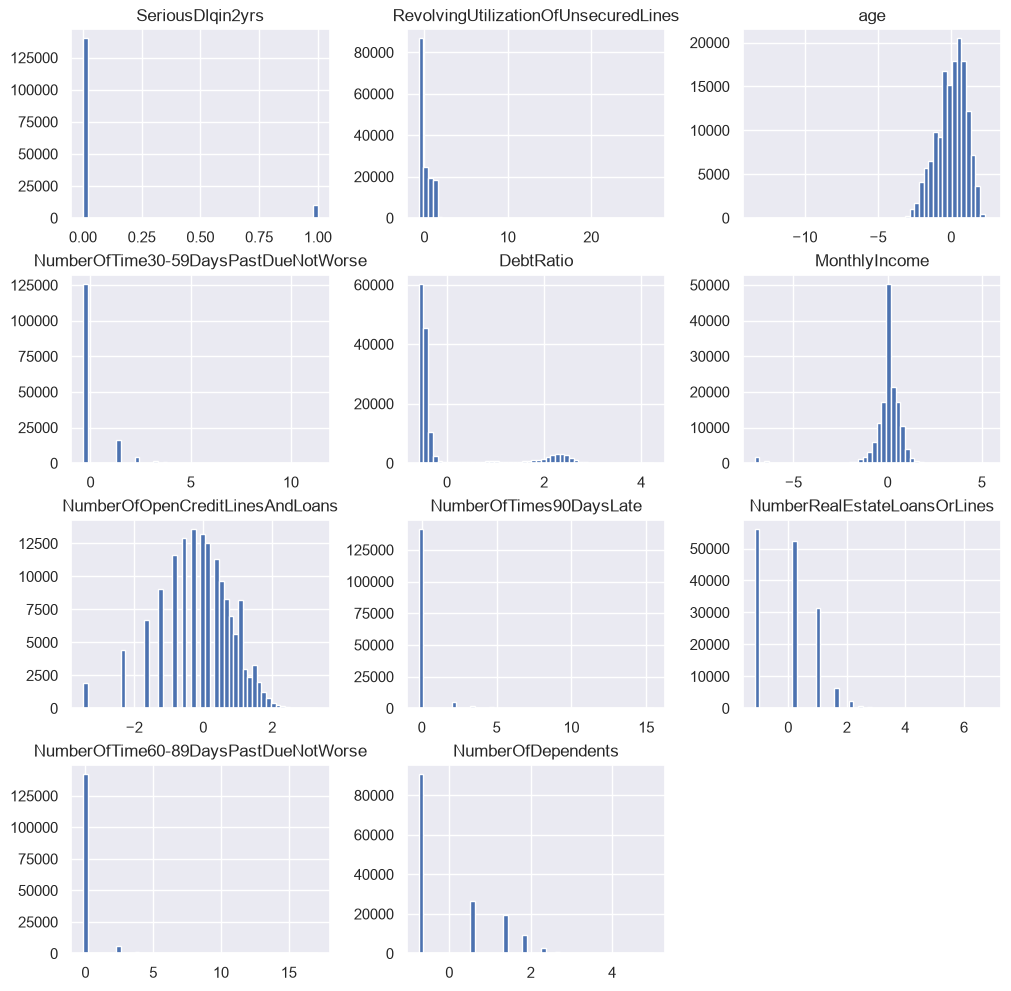

In [11]:
train_df.hist(bins=50, figsize=(12, 12));